# Online Shoppers Purchasing Intention Prediction Using Machine Learning
### Supervised Binary Classification on E-Commerce Visitor Sessions
**Academic Project** | Computer Science & Engineering  
**Dataset:** Online Shoppers Purchasing Intention Dataset (UCI Machine Learning Repository, ID: 468)  
**Target Variable:** `Revenue` (True / False)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

## Project Overview and Motivation
In modern e-commerce systems, understanding customer purchasing intention during active browsing sessions is essential for:
1. **Dynamic Real-Time Personalization:** Offering tailored discounts or assistance to users showing purchase intent.
2. **Resource Optimization:** Allocating promotional incentives and targeted remarketing budgets efficiently.
3. **Checkout Abandonment Reduction:** Intervening before high-intent shoppers exit the website.

This project implements an end-to-end Machine Learning pipeline to classify whether an online visitor session will generate **Revenue** (`Revenue = 1`) or not (`Revenue = 0`).

### Mandatory Algorithms Evaluated:
1. **Logistic Regression** (Linear baseline with sigmoid activation)
2. **K-Nearest Neighbors (KNN)** (Non-parametric instance-based metric learning)
3. **Decision Tree Classifier** (Non-linear recursive partitioning)
4. **Random Forest Classifier** (Bagged ensemble of decision trees)

---

## Section 1: Dataset Loading & Initial Inspection

### Objectives:
- Import essential scientific and machine learning libraries.
- Load the Online Shoppers Purchasing Intention Dataset from the UCI Machine Learning Repository (or local fallback).
- Inspect dataset dimensions, column names, head samples, and data types.

In [1]:
# 1.1 Import Necessary Python Libraries
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn imports for preprocessing, pipelines, models, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Configure plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
# 1.2 Automated Dataset Loading (Google Colab & Offline Compatible)
dataset_filename = 'online_shoppers_intention.csv'
dataset_url = 'https://raw.githubusercontent.com/sharmaroshan/Online-Shoppers-Purchasing-Intention/master/online_shoppers_intention.csv'

# Download the dataset if not already present in the workspace
if not os.path.exists(dataset_filename):
    print(f"Downloading dataset from: {dataset_url}")
    urllib.request.urlretrieve(dataset_url, dataset_filename)
    print("Download completed.")
else:
    print(f"Found local copy of dataset: {dataset_filename}")

# Load into Pandas DataFrame
df = pd.read_csv(dataset_filename)
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.")

Found local copy of dataset: online_shoppers_intention.csv
Dataset successfully loaded. Dimensions: 12330 rows, 18 columns.


In [3]:
# 1.3 Display First 5 Rows of the Dataset
df.head()

In [4]:
# 1.4 Dataset Dimensions and Column Names
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")
print("Column Names:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")

Dataset Shape: 12330 rows and 18 columns

Column Names:
   1. Administrative
   2. Administrative_Duration
   3. Informational
   4. Informational_Duration
   5. ProductRelated
   6. ProductRelated_Duration
   7. BounceRates
   8. ExitRates
   9. PageValues
  10. SpecialDay
  11. Month
  12. OperatingSystems
  13. Browser
  14. Region
  15. TrafficType
  16. VisitorType
  17. Weekend
  18. Revenue


In [5]:
# 1.5 Dataset Information, Data Types, and Non-Null Counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

## Section 2: Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps uncover statistical characteristics, class distributions, potential anomalies, and correlations with the target variable `Revenue`.

In [6]:
# 2.1 Descriptive Statistics of Numerical Features
df.describe().T

In [7]:
# 2.2 Identify Numerical and Categorical Features
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f"Numerical Features ({len(numerical_features)}):\n  {numerical_features}\n")
print(f"Categorical & Boolean Features ({len(categorical_features)}):\n  {categorical_features}")

Numerical Features (14):
  ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical & Boolean Features (4):
  ['Month', 'VisitorType', 'Weekend', 'Revenue']


In [8]:
# 2.3 Check for Missing Values and Duplicate Records
missing_counts = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print("Missing Values per Column:")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "  No missing values found across all columns.")
print(f"\nTotal Duplicate Rows Found: {duplicate_count} ({duplicate_count / len(df) * 100:.2f}% of dataset)")

Missing Values per Column:
  No missing values found across all columns.

Total Duplicate Rows Found: 125 (1.01% of dataset)


Target Class Breakdown:
  No Purchase (False): 10,422 sessions (84.53%)
  Purchase (True):    1,908 sessions (15.47%)

Observation: High class imbalance (~84.5% vs ~15.5%). Evaluation must prioritize Precision, Recall, and F1-Score.


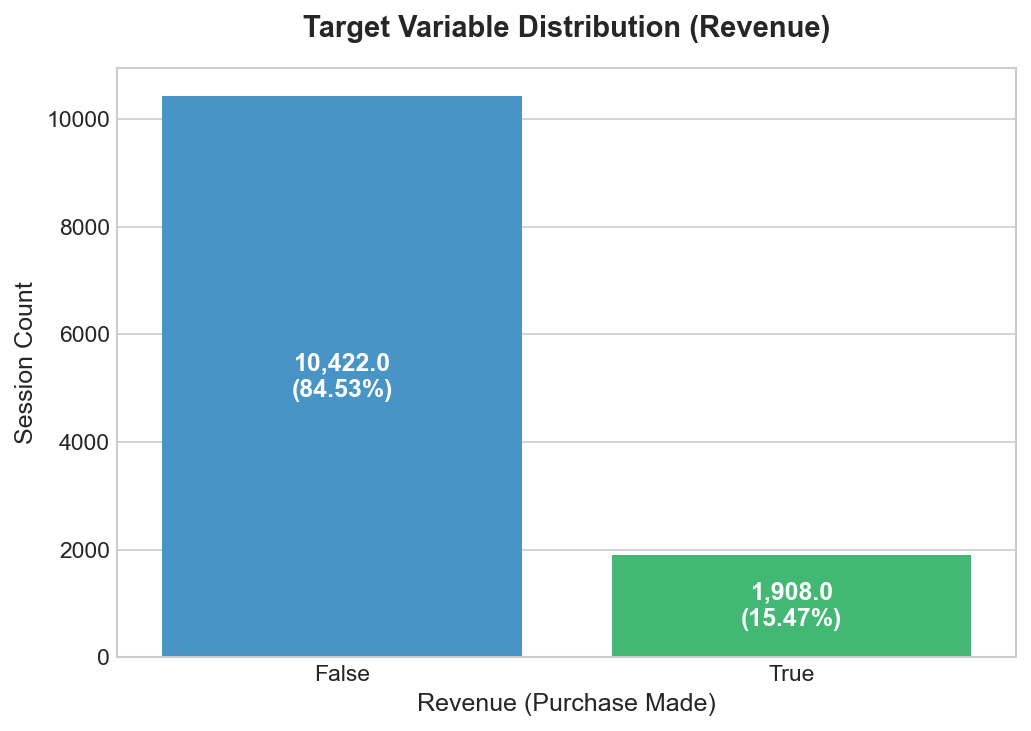

In [9]:
# 2.4 Visualize Target Variable Distribution (Revenue)
plt.figure(figsize=(7, 5))
revenue_counts = df['Revenue'].value_counts()
colors = ['#3498db', '#2ecc71']

ax = sns.countplot(data=df, x='Revenue', palette=colors, hue='Revenue', legend=False)
plt.title('Target Variable Distribution (Revenue)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Revenue (Purchase Made)', fontsize=12)
plt.ylabel('Session Count', fontsize=12)

total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f"{100 * height / total:.2f}%"
    ax.annotate(f"{height:,}\n({percentage})",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

print("Target Class Breakdown:")
print(f"  No Purchase (False): {revenue_counts[False]:,} sessions ({revenue_counts[False]/total*100:.2f}%)")
print(f"  Purchase (True):    {revenue_counts[True]:,} sessions ({revenue_counts[True]/total*100:.2f}%)")
print("\nObservation: High class imbalance (~84.5% vs ~15.5%). Evaluation must prioritize Precision, Recall, and F1-Score.")

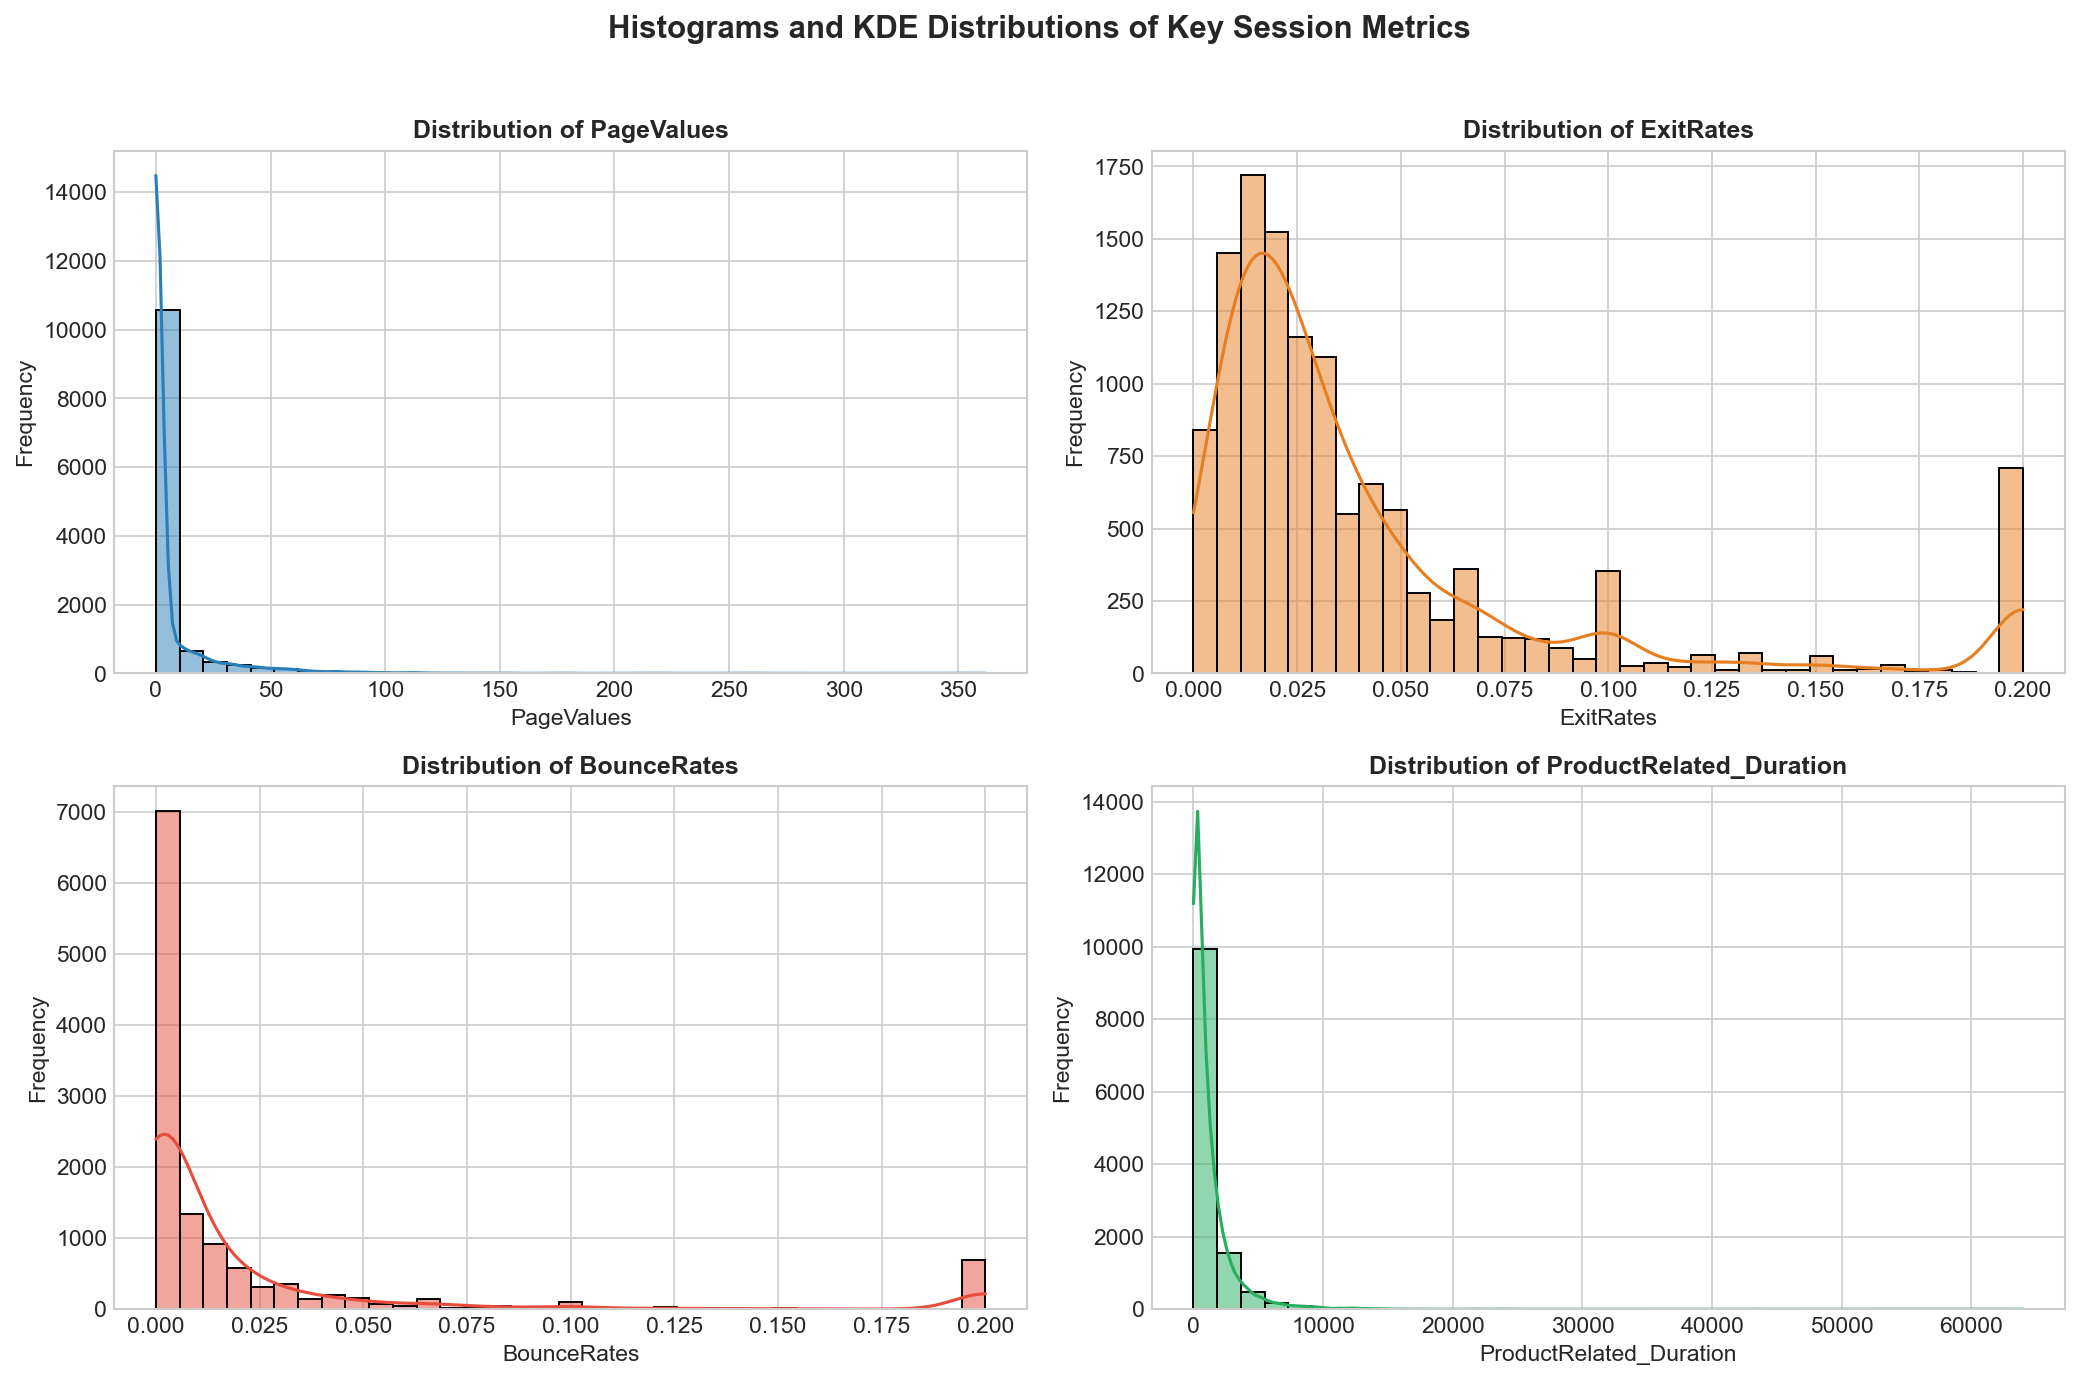

In [10]:
# 2.5 Distribution of Key Numerical Features
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
key_numeric = ['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration']
plot_colors = ['#2980b9', '#e67e22', '#e74c3c', '#27ae60']

for i, col in enumerate(key_numeric):
    ax = axes[i // 2, i % 2]
    sns.histplot(df[col], kde=True, ax=ax, color=plot_colors[i], bins=35)
    ax.set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)

plt.suptitle('Histograms and KDE Distributions of Key Session Metrics', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Key Correlation Insights:
1. BounceRates and ExitRates show a strong positive correlation (~0.91), as sessions bouncing on the first page also register as exit pages.
2. ProductRelated and ProductRelated_Duration show high correlation (~0.86), representing browsing depth.


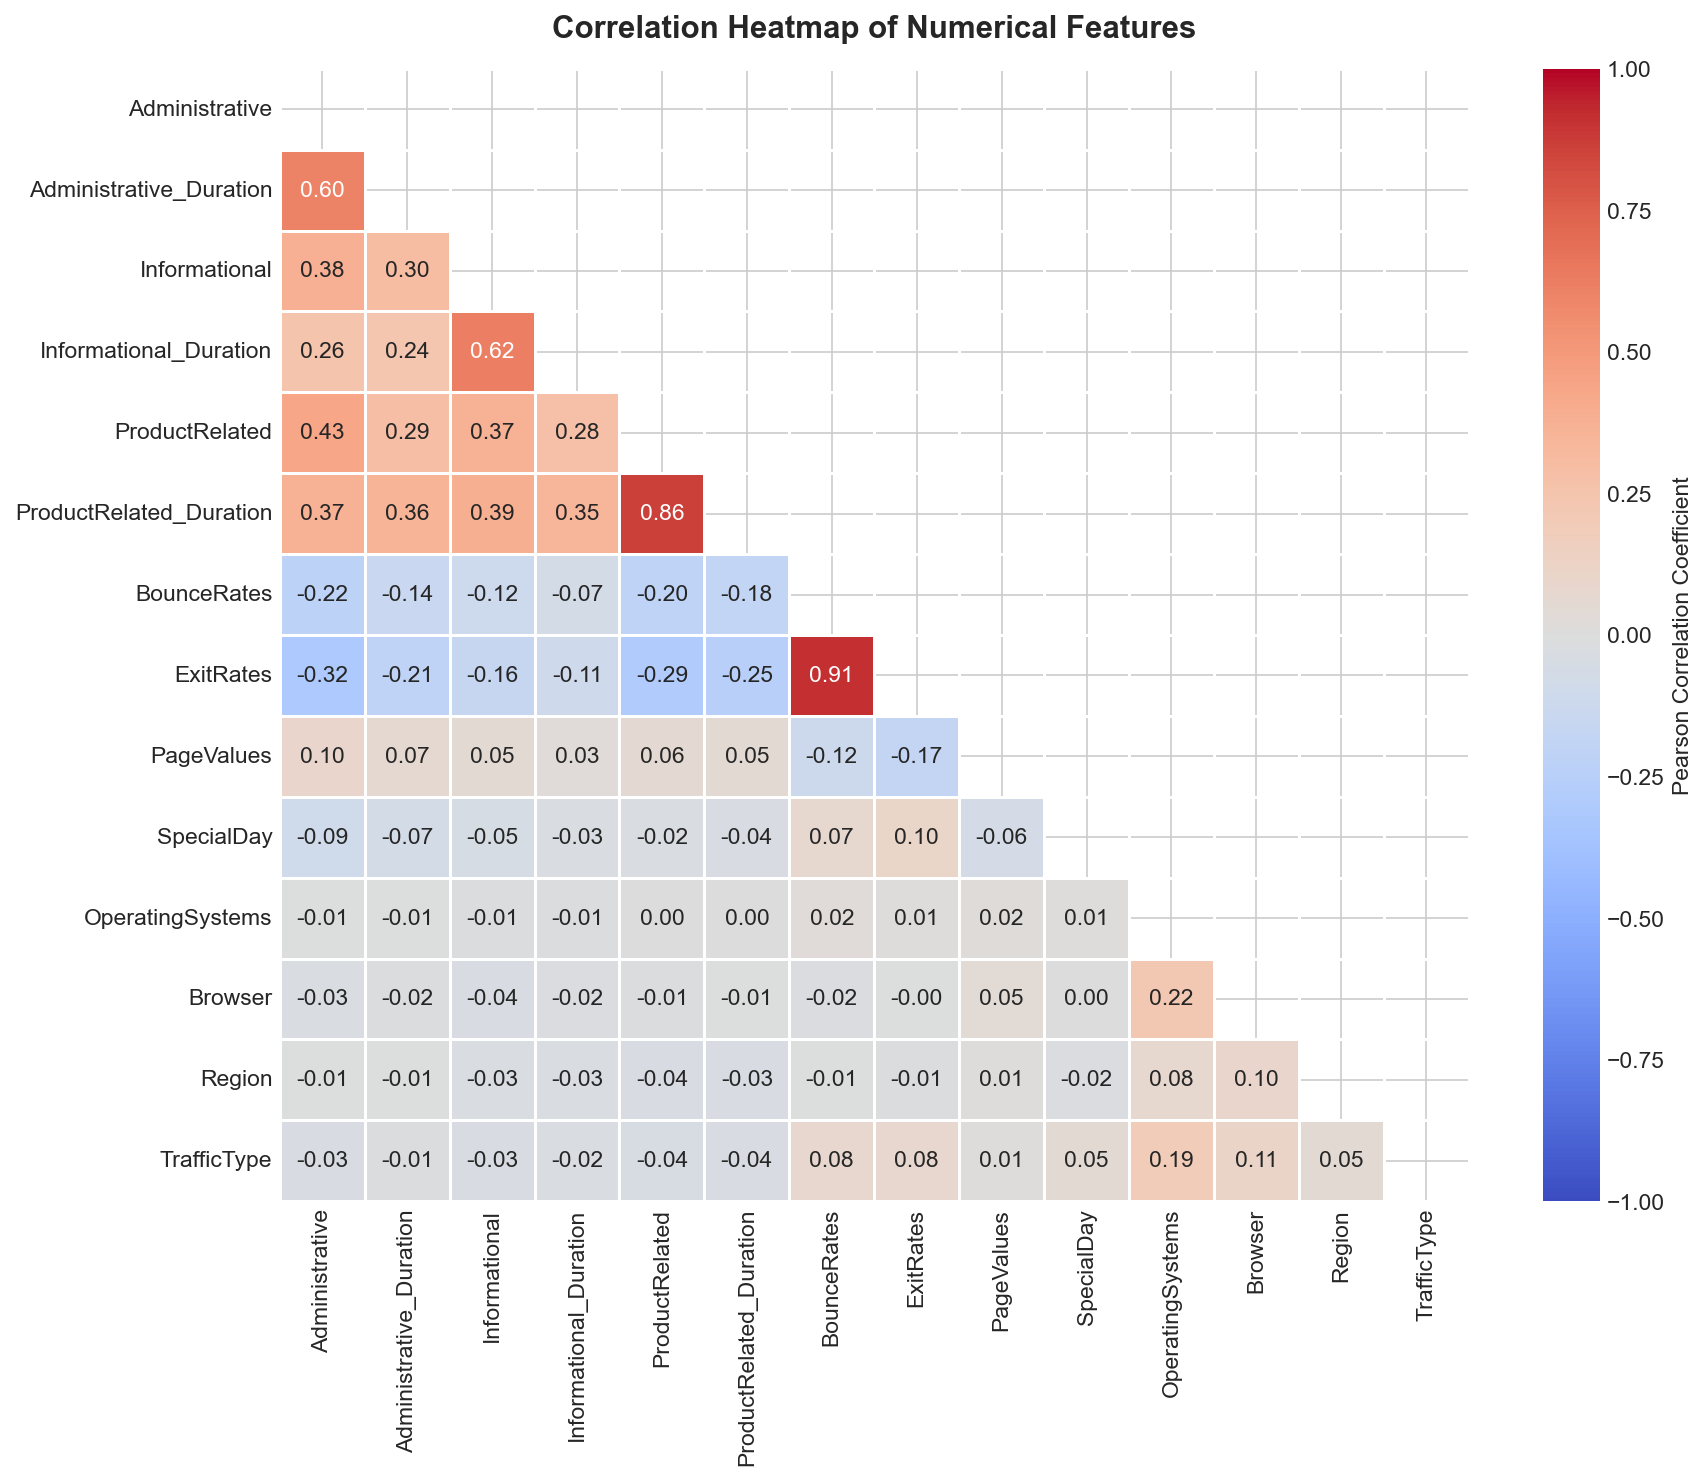

In [11]:
# 2.6 Correlation Heatmap of Numerical Features
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Correlation Heatmap of Numerical Features', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("Key Correlation Insights:")
print("1. BounceRates and ExitRates show a strong positive correlation (~0.91), as sessions bouncing on the first page also register as exit pages.")
print("2. ProductRelated and ProductRelated_Duration show high correlation (~0.86), representing browsing depth.")

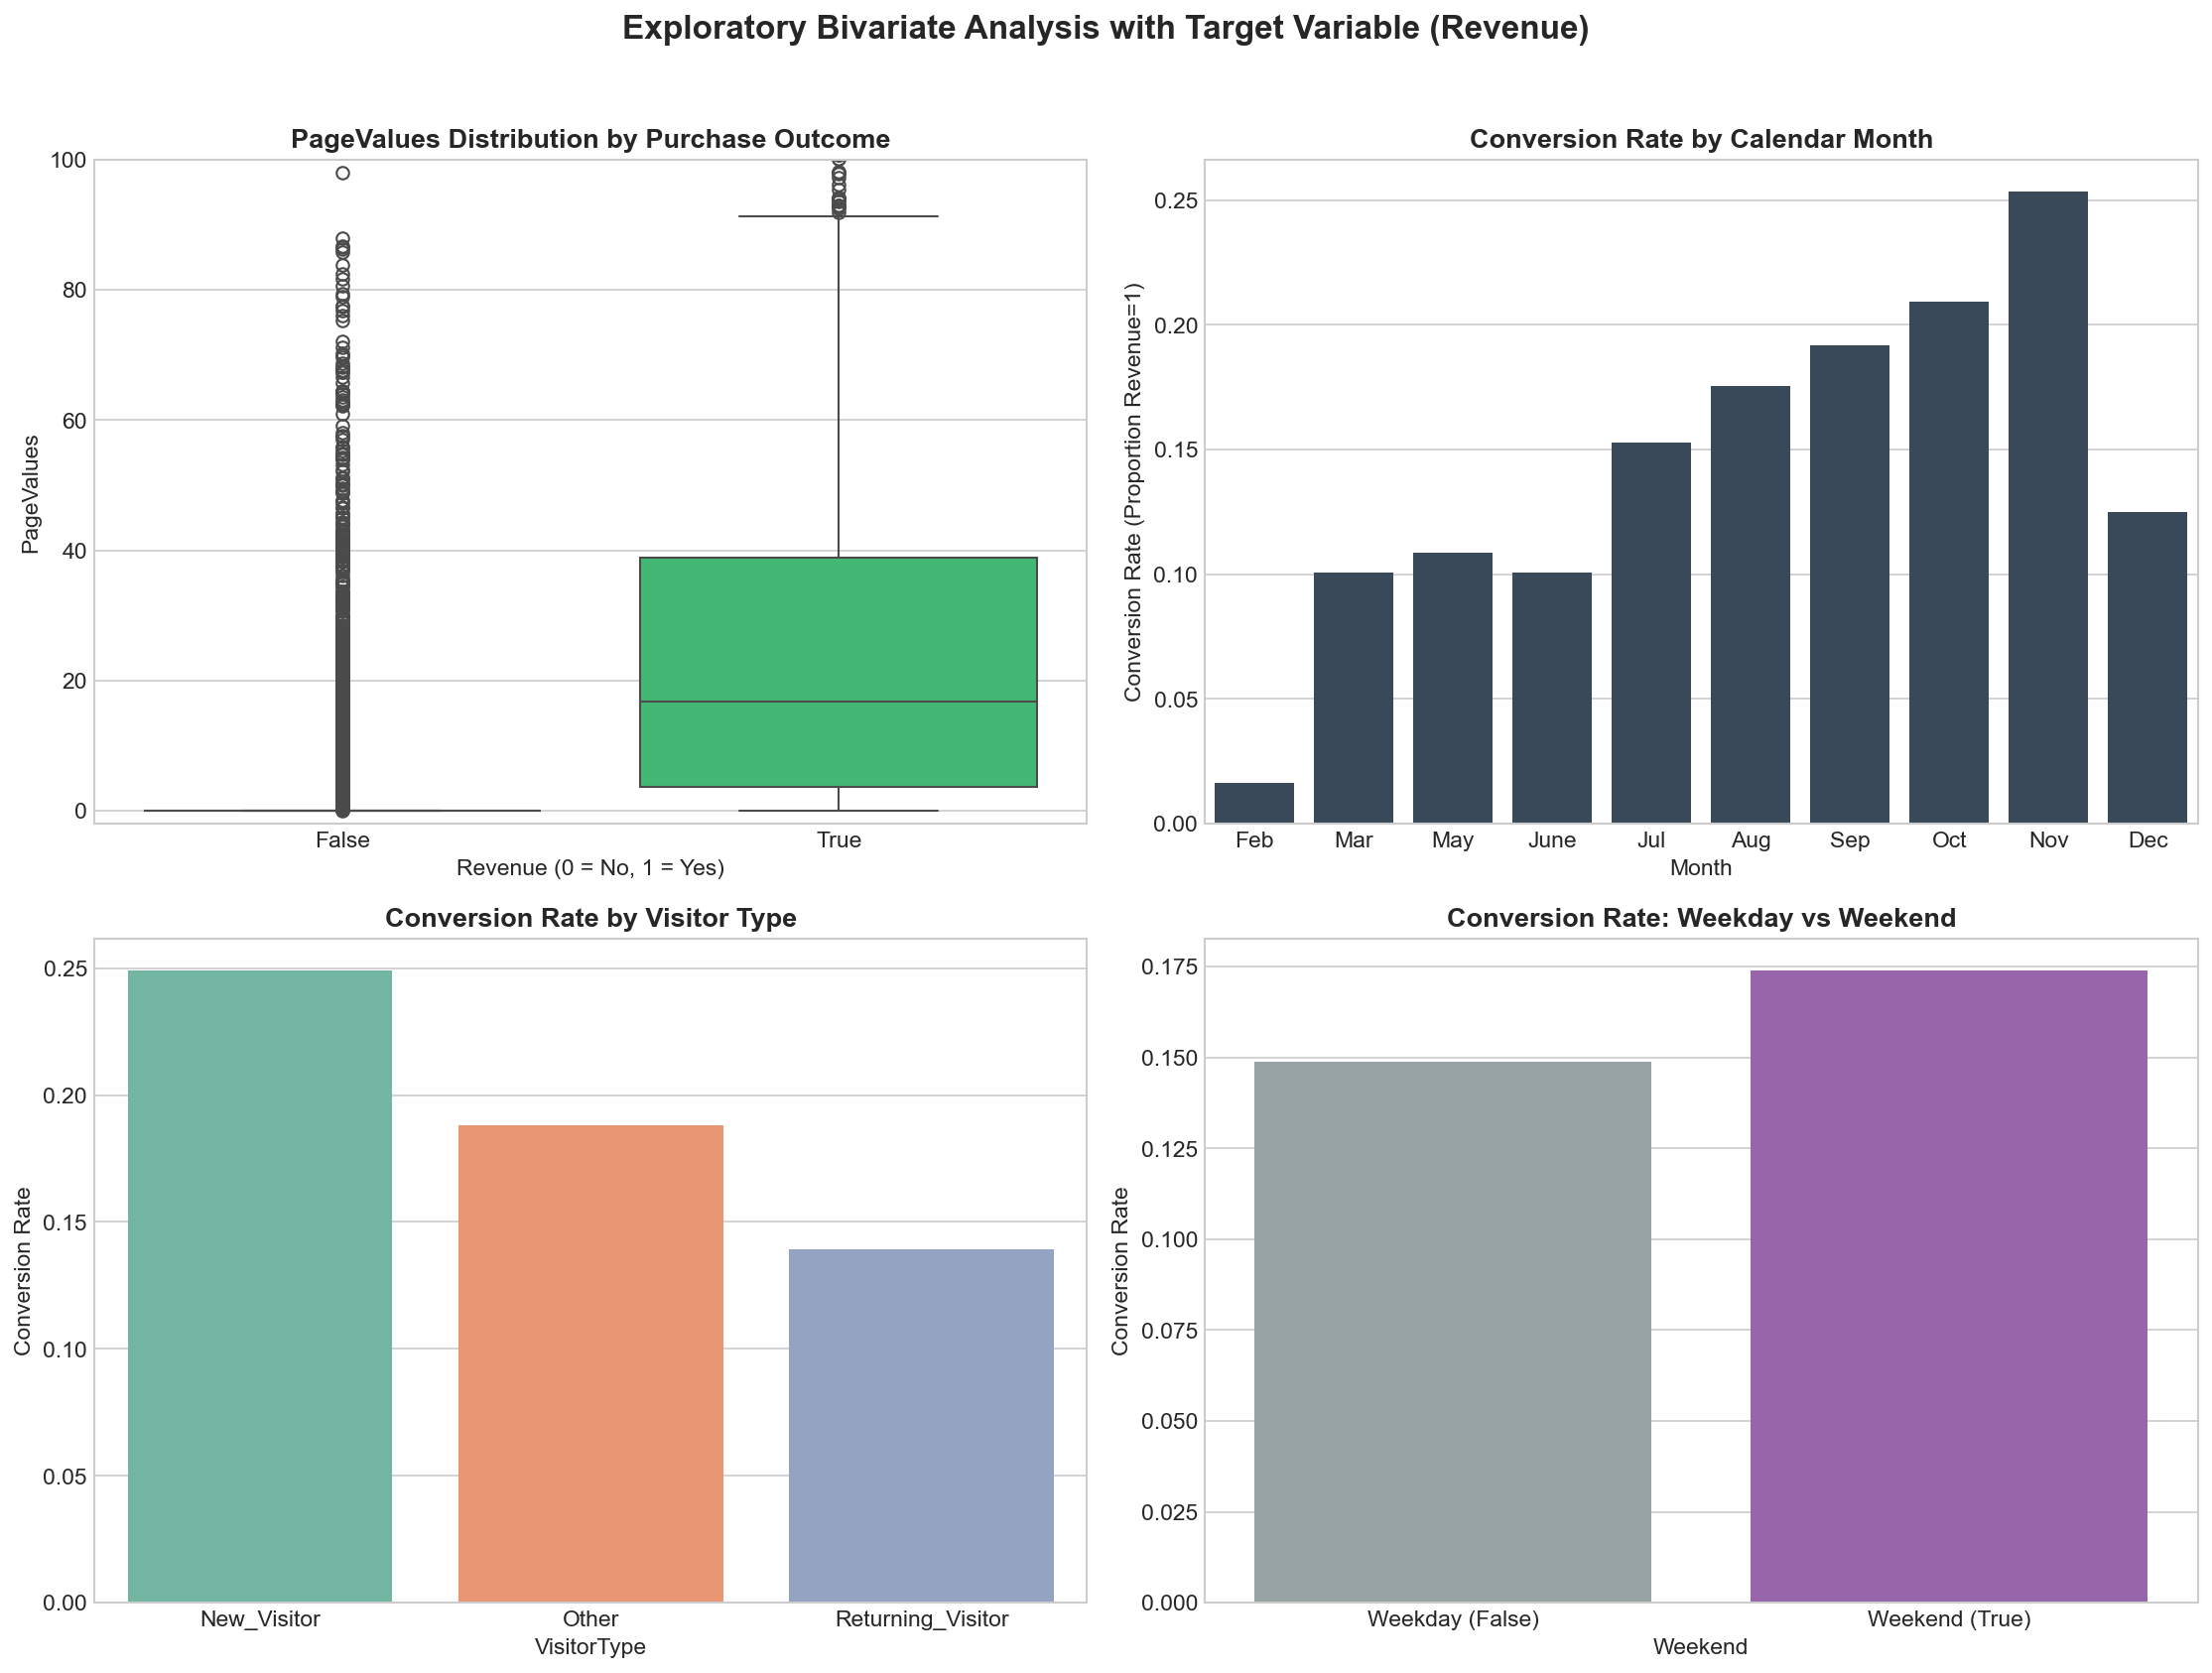

In [12]:
# 2.7 Bivariate Analysis: Relationship Between Important Features and Revenue
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# A. PageValues vs Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', palette=['#3498db', '#2ecc71'], hue='Revenue', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('PageValues Distribution by Purchase Outcome', fontsize=13, fontweight='bold')
axes[0, 0].set_ylim(-2, 100) # zoom in on primary density
axes[0, 0].set_xlabel('Revenue (0 = No, 1 = Yes)')

# B. Conversion Rate across Months
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
conv_by_month = df.groupby('Month')['Revenue'].mean().reindex(month_order).reset_index()
sns.barplot(data=conv_by_month, x='Month', y='Revenue', color='#34495e', ax=axes[0, 1])
axes[0, 1].set_title('Conversion Rate by Calendar Month', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Conversion Rate (Proportion Revenue=1)')

# C. Visitor Type vs Revenue
conv_by_visitor = df.groupby('VisitorType')['Revenue'].mean().reset_index()
sns.barplot(data=conv_by_visitor, x='VisitorType', y='Revenue', palette='Set2', hue='VisitorType', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Conversion Rate by Visitor Type', fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel('Conversion Rate')

# D. Weekend Browsing vs Revenue
conv_by_weekend = df.groupby('Weekend')['Revenue'].mean().reset_index()
sns.barplot(data=conv_by_weekend, x='Weekend', y='Revenue', palette=['#95a5a6', '#9b59b6'], hue='Weekend', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Conversion Rate: Weekday vs Weekend', fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel('Conversion Rate')
axes[1, 1].set_xticklabels(['Weekday (False)', 'Weekend (True)'])

plt.suptitle('Exploratory Bivariate Analysis with Target Variable (Revenue)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Section 3: Data Preprocessing

Data preprocessing prepares raw web traffic records for algorithmic modeling:
1. **Deduplication:** Remove identical duplicate records that cause bias or artificial certainty.
2. **Type Casting:** Convert boolean variables (`Weekend`, `Revenue`) to numerical binary flags (0 and 1).
3. **Categorical Encoding:** One-Hot Encode string categories (`Month`, `VisitorType`) using Scikit-Learn `OneHotEncoder(drop='first')` to prevent the dummy variable trap.
4. **Stratified Split (80:20):** Preserve minority class proportion across training and testing splits.
5. **Feature Scaling & Leakage Prevention:** Apply `StandardScaler` fitted **strictly on training data** and transformed on test data via Scikit-Learn `Pipeline`.

In [13]:
# 3.1 Handle Duplicates and Missing Values
df_clean = df.copy()

before_len = len(df_clean)
df_clean = df_clean.drop_duplicates()
after_len = len(df_clean)
print(f"Removed {before_len - after_len} duplicate records. Clean dataset size: {after_len} rows.")
print(f"Remaining Missing Values: {df_clean.isnull().sum().sum()}")

Removed 125 duplicate records. Clean dataset size: 12205 rows.
Remaining Missing Values: 0


In [14]:
# 3.2 Convert Boolean Columns to Numerical Form
df_clean['Weekend'] = df_clean['Weekend'].astype(int)
df_clean['Revenue'] = df_clean['Revenue'].astype(int)

print("Target variable 'Revenue' distribution in clean dataset:")
print(df_clean['Revenue'].value_counts())

Target variable 'Revenue' distribution in clean dataset:
Revenue
0    10297
1     1908
Name: count, dtype: int64


In [15]:
# 3.3 Feature Matrix (X) and Target Vector (y) Separation
X = df_clean.drop('Revenue', axis=1)
y = df_clean['Revenue']

categorical_cols = ['Month', 'VisitorType']
numerical_cols = [c for c in X.columns if c not in categorical_cols]

print(f"Target vector y shape: {y.shape}")
print(f"Feature matrix X shape: {X.shape}")
print(f"Categorical features to encode ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical/Ordinal features ({len(numerical_cols)}): {numerical_cols}")

Target vector y shape: (12205,)
Feature matrix X shape: (12205, 17)
Categorical features to encode (2): ['Month', 'VisitorType']
Numerical/Ordinal features (15): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']


In [16]:
# 3.4 Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples ({X_train.shape[0] / len(X) * 100:.1f}%)")
print(f"Testing set size:  {X_test.shape[0]} samples ({X_test.shape[0] / len(X) * 100:.1f}%)")

print("\nClass Proportions Check:")
print("  Train set positive class (Revenue=1):", f"{y_train.mean()*100:.2f}%")
print("  Test set positive class  (Revenue=1):", f"{y_test.mean()*100:.2f}%")

Training set size: 9764 samples (80.0%)
Testing set size:  2441 samples (20.0%)

Class Proportions Check:
  Train set positive class (Revenue=1): 15.63%
  Test set positive class  (Revenue=1): 15.65%


In [17]:
# 3.5 Construct Scikit-Learn Preprocessing Pipelines (Preventing Data Leakage)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

print("Scikit-Learn ColumnTransformers configured:")
print("  1. 'preprocessor_scaled': StandardScaler for numerical features + OneHotEncoder for categoricals")
print("  2. 'preprocessor_unscaled': Passthrough numerical features + OneHotEncoder for categoricals")

Scikit-Learn ColumnTransformers configured:
  1. 'preprocessor_scaled': StandardScaler for numerical features + OneHotEncoder for categoricals
  2. 'preprocessor_unscaled': Passthrough numerical features + OneHotEncoder for categoricals


## Section 4: Model Implementation

We implement each of the four mandatory algorithms independently using Scikit-Learn `Pipeline`.
A Pipeline bundles preprocessing and model estimation into an atomic, reproducible object, guaranteeing that test data is never leaked into training steps.

### Algorithms:
1. **Logistic Regression:** Linear classifier modeling log-odds of purchase via sigmoid function.
2. **K-Nearest Neighbors (KNN):** Distance-based non-parametric classifier using k=5 nearest neighbors.
3. **Decision Tree Classifier:** Tree-structured model using recursive Gini impurity splits.
4. **Random Forest Classifier:** Bagged ensemble of 100 decision trees with feature subsampling.

In [18]:
# Dictionary to store trained pipelines and performance records
trained_pipelines = {}
model_evaluations = []
confusion_matrices = {}

In [19]:
# 4.1 Model 1: Logistic Regression
print("--- Training Model 1: Logistic Regression ---")
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train on training set
lr_pipeline.fit(X_train, y_train)

# Predict on testing set
y_pred_lr = lr_pipeline.predict(X_test)

# Record pipeline
trained_pipelines['Logistic Regression'] = lr_pipeline

# Evaluation
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)
confusion_matrices['Logistic Regression'] = cm_lr

model_evaluations.append({
    'Model': 'Logistic Regression',
    'Accuracy': acc_lr,
    'Precision': prec_lr,
    'Recall': rec_lr,
    'F1-Score': f1_lr
})

print(f"Logistic Regression Results:")
print(f"  Accuracy:  {acc_lr:.4f}")
print(f"  Precision: {prec_lr:.4f}")
print(f"  Recall:    {rec_lr:.4f}")
print(f"  F1-Score:  {f1_lr:.4f}")
print("Confusion Matrix:")
print(cm_lr)

--- Training Model 1: Logistic Regression ---
Logistic Regression Results:
  Accuracy:  0.8894
  Precision: 0.7718
  Recall:    0.4162
  F1-Score:  0.5408
Confusion Matrix:
[[2012   47]
 [ 223  159]]


In [20]:
# 4.2 Model 2: K-Nearest Neighbors (KNN)
print("--- Training Model 2: K-Nearest Neighbors (KNN) ---")
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train on training set
knn_pipeline.fit(X_train, y_train)

# Predict on testing set
y_pred_knn = knn_pipeline.predict(X_test)

# Record pipeline
trained_pipelines['KNN'] = knn_pipeline

# Evaluation
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
cm_knn = confusion_matrix(y_test, y_pred_knn)
confusion_matrices['KNN'] = cm_knn

model_evaluations.append({
    'Model': 'K-Nearest Neighbors (KNN)',
    'Accuracy': acc_knn,
    'Precision': prec_knn,
    'Recall': rec_knn,
    'F1-Score': f1_knn
})

print(f"KNN Results:")
print(f"  Accuracy:  {acc_knn:.4f}")
print(f"  Precision: {prec_knn:.4f}")
print(f"  Recall:    {rec_knn:.4f}")
print(f"  F1-Score:  {f1_knn:.4f}")
print("Confusion Matrix:")
print(cm_knn)

--- Training Model 2: K-Nearest Neighbors (KNN) ---
KNN Results:
  Accuracy:  0.8759
  Precision: 0.6710
  Recall:    0.4058
  F1-Score:  0.5057
Confusion Matrix:
[[1983   76]
 [ 227  155]]


In [21]:
# 4.3 Model 3: Decision Tree Classifier
print("--- Training Model 3: Decision Tree Classifier ---")
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Train on training set
dt_pipeline.fit(X_train, y_train)

# Predict on testing set
y_pred_dt = dt_pipeline.predict(X_test)

# Record pipeline
trained_pipelines['Decision Tree'] = dt_pipeline

# Evaluation
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)
confusion_matrices['Decision Tree'] = cm_dt

model_evaluations.append({
    'Model': 'Decision Tree',
    'Accuracy': acc_dt,
    'Precision': prec_dt,
    'Recall': rec_dt,
    'F1-Score': f1_dt
})

print(f"Decision Tree Results:")
print(f"  Accuracy:  {acc_dt:.4f}")
print(f"  Precision: {prec_dt:.4f}")
print(f"  Recall:    {rec_dt:.4f}")
print(f"  F1-Score:  {f1_dt:.4f}")
print("Confusion Matrix:")
print(cm_dt)

--- Training Model 3: Decision Tree Classifier ---
Decision Tree Results:
  Accuracy:  0.8603
  Precision: 0.5535
  Recall:    0.5550
  F1-Score:  0.5542
Confusion Matrix:
[[1888  171]
 [ 170  212]]


In [22]:
# 4.4 Model 4: Random Forest Classifier
print("--- Training Model 4: Random Forest Classifier ---")
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train on training set
rf_pipeline.fit(X_train, y_train)

# Predict on testing set
y_pred_rf = rf_pipeline.predict(X_test)

# Record pipeline
trained_pipelines['Random Forest'] = rf_pipeline

# Evaluation
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)
confusion_matrices['Random Forest'] = cm_rf

model_evaluations.append({
    'Model': 'Random Forest',
    'Accuracy': acc_rf,
    'Precision': prec_rf,
    'Recall': rec_rf,
    'F1-Score': f1_rf
})

print(f"Random Forest Results:")
print(f"  Accuracy:  {acc_rf:.4f}")
print(f"  Precision: {prec_rf:.4f}")
print(f"  Recall:    {rec_rf:.4f}")
print(f"  F1-Score:  {f1_rf:.4f}")
print("Confusion Matrix:")
print(cm_rf)

--- Training Model 4: Random Forest Classifier ---
Random Forest Results:
  Accuracy:  0.9078
  Precision: 0.7661
  Recall:    0.5916
  F1-Score:  0.6677
Confusion Matrix:
[[1990   69]
 [ 156  226]]


## Section 5: Model Evaluation & Classification Reports

Because the positive class (`Revenue = 1`) represents only ~15.6% of sessions, **Accuracy alone is a misleading metric**.
A trivial baseline predicting "No Purchase" (0) for every session would achieve ~84.4% accuracy while detecting **zero** buyers.

Therefore, we evaluate:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Of all sessions predicted as purchases, what fraction actually bought? (Minimizes False Positives / wasted discounts).
- **Recall (Sensitivity):** Of all actual buyers, what fraction did the model successfully identify? (Minimizes False Negatives / missed revenue).
- **F1-Score:** The harmonic mean of Precision and Recall.

In [23]:
# 5.1 Comprehensive Classification Reports for All Four Models
predictions_dict = {
    'Logistic Regression': y_pred_lr,
    'K-Nearest Neighbors (KNN)': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf
}

for model_name, preds in predictions_dict.items():
    print(f"============================================================")
    print(f"CLASSIFICATION REPORT: {model_name.upper()}")
    print(f"============================================================")
    print(classification_report(y_test, preds, target_names=['No Purchase (0)', 'Purchase (1)'], digits=4))
    print()

CLASSIFICATION REPORT: LOGISTIC REGRESSION
                 precision    recall  f1-score   support

No Purchase (0)     0.9002    0.9772    0.9371      2059
   Purchase (1)     0.7718    0.4162    0.5408       382

       accuracy                         0.8894      2441
      macro avg     0.8360    0.6967    0.7390      2441
   weighted avg     0.8801    0.8894    0.8751      2441


CLASSIFICATION REPORT: K-NEAREST NEIGHBORS (KNN)
                 precision    recall  f1-score   support

No Purchase (0)     0.8973    0.9631    0.9290      2059
   Purchase (1)     0.6710    0.4058    0.5057       382

       accuracy                         0.8759      2441
      macro avg     0.7841    0.6844    0.7174      2441
   weighted avg     0.8619    0.8759    0.8628      2441


CLASSIFICATION REPORT: DECISION TREE
                 precision    recall  f1-score   support

No Purchase (0)     0.9174    0.9169    0.9172      2059
   Purchase (1)     0.5535    0.5550    0.5542       382

      

## Section 6: Comparative Analysis

Here we consolidate the evaluation metrics, visualize performance across algorithms, inspect the four confusion matrices side-by-side, and identify the top features influencing purchasing intention.

In [24]:
# 6.1 Comparison Table of All Four Algorithms
comparison_df = pd.DataFrame(model_evaluations)
comparison_df = comparison_df.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

display_df = comparison_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    display_df[col] = display_df[col].apply(lambda x: f"{x * 100:.2f}%")

print("EVALUATION METRICS COMPARISON TABLE (Ranked by F1-Score):")
display_df

EVALUATION METRICS COMPARISON TABLE (Ranked by F1-Score):


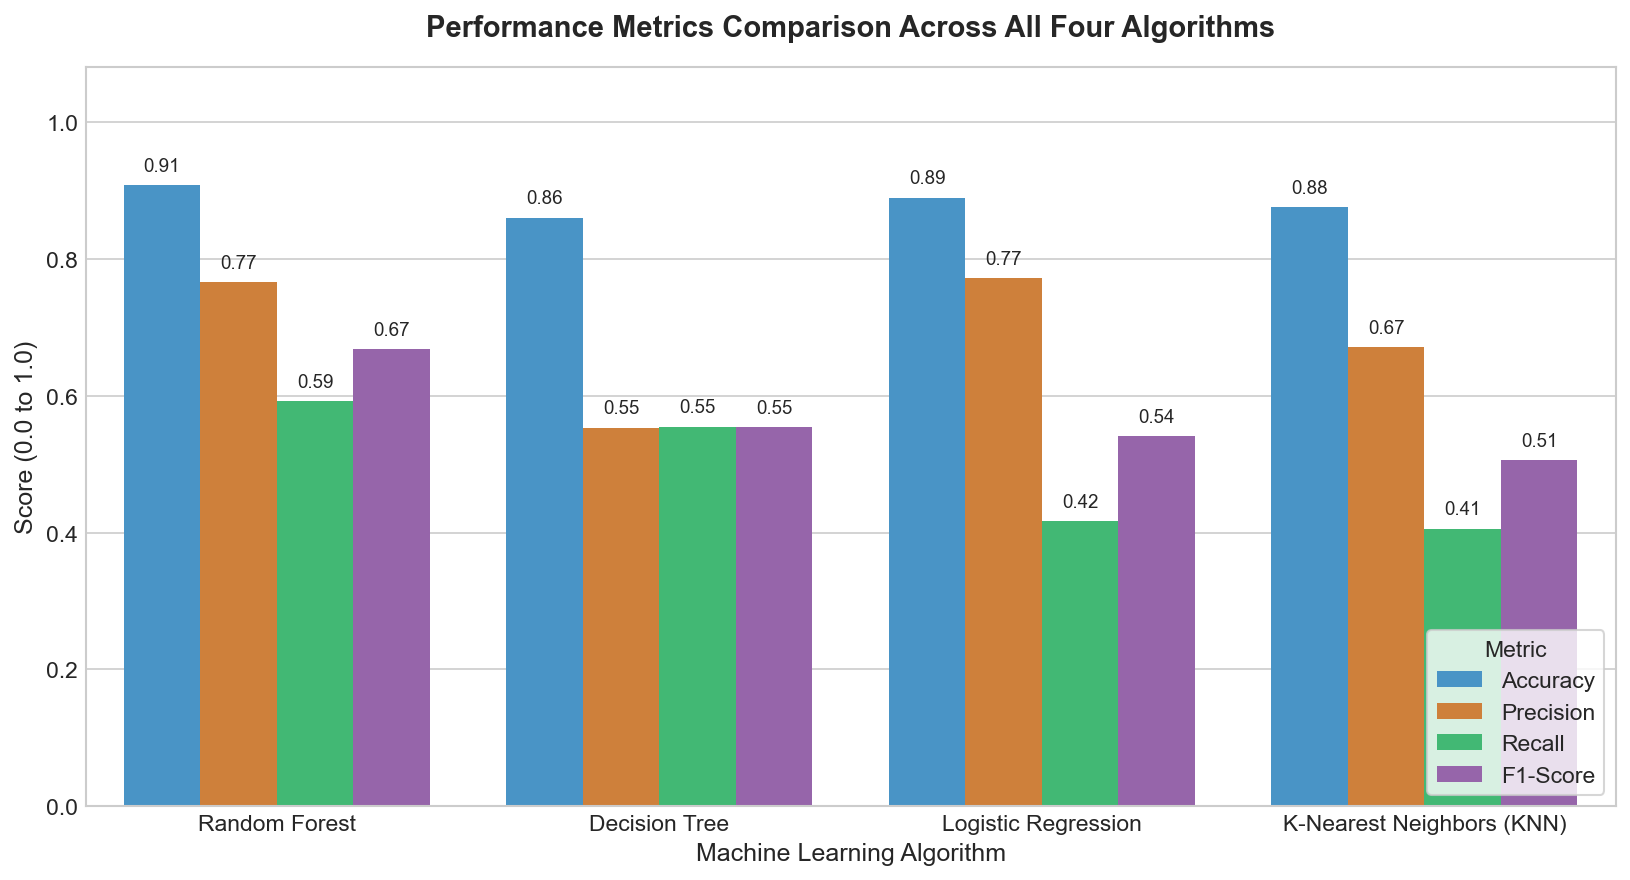

In [25]:
# 6.2 Grouped Bar Chart Comparison of All Four Metrics
plt.figure(figsize=(11, 6))

melted_df = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
palette = ['#3498db', '#e67e22', '#2ecc71', '#9b59b6']

ax = sns.barplot(data=melted_df, x='Model', y='Score', hue='Metric', palette=palette)
plt.title('Performance Metrics Comparison Across All Four Algorithms', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Machine Learning Algorithm', fontsize=12)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12)
plt.ylim(0, 1.08)
plt.legend(title='Metric', loc='lower right', frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height + 0.015),
                    ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

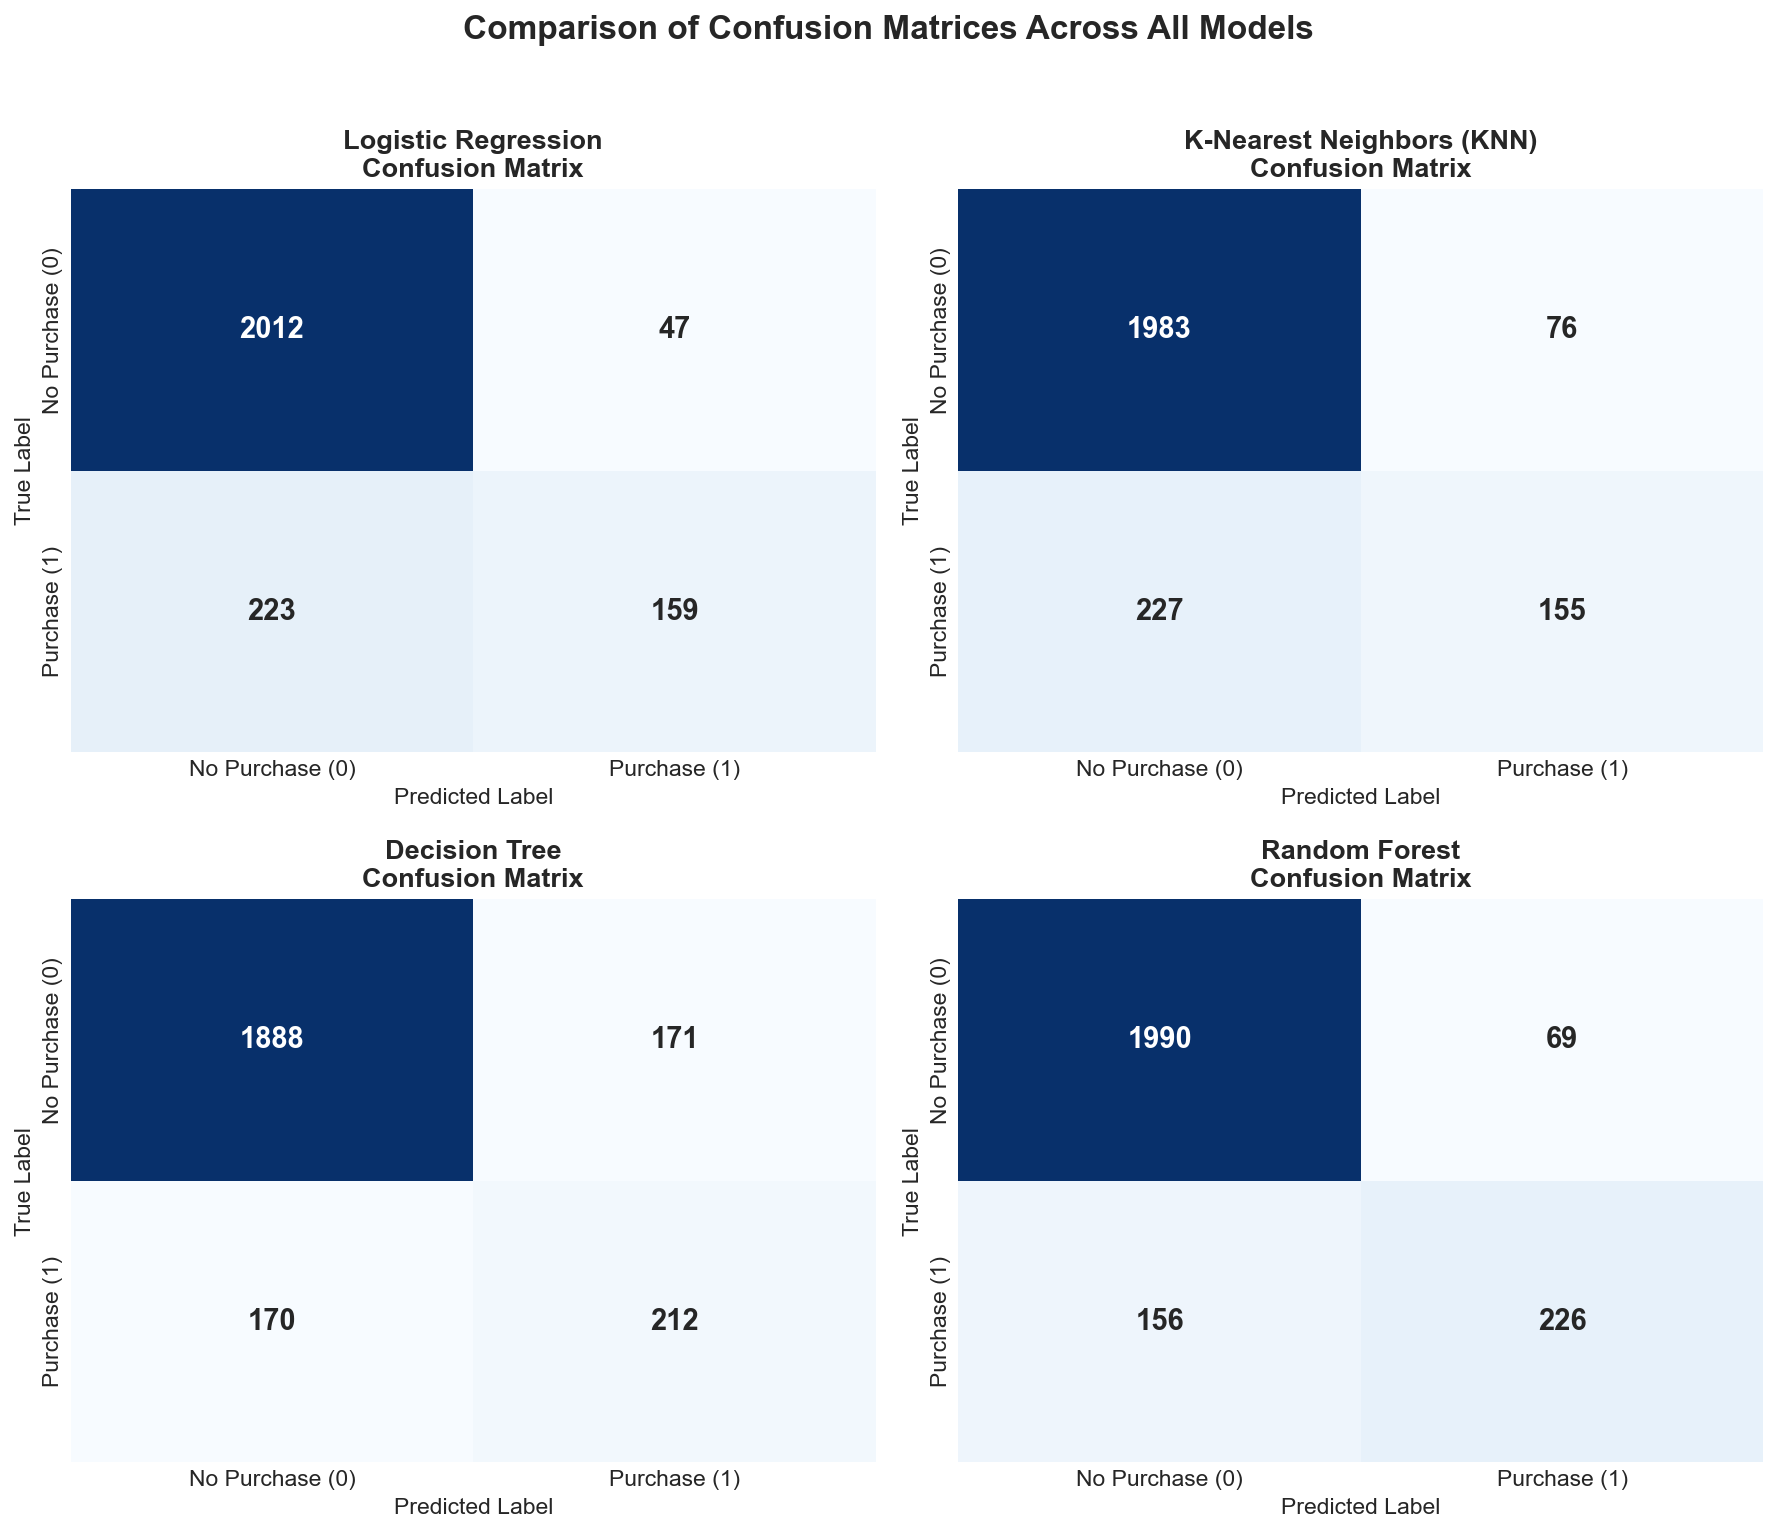

In [26]:
# 6.3 Side-by-Side Confusion Matrices (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

model_keys = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest']
cm_titles = ['Logistic Regression', 'K-Nearest Neighbors (KNN)', 'Decision Tree', 'Random Forest']

for idx, key in enumerate(model_keys):
    cm = confusion_matrices[key]
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[idx],
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    axes[idx].set_title(f"{cm_titles[idx]}\nConfusion Matrix", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontsize=11)
    axes[idx].set_ylabel('True Label', fontsize=11)
    axes[idx].set_xticklabels(['No Purchase (0)', 'Purchase (1)'])
    axes[idx].set_yticklabels(['No Purchase (0)', 'Purchase (1)'])

plt.suptitle('Comparison of Confusion Matrices Across All Models', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Top 5 Driving Features:
  1. PageValues: 0.3645
  2. ProductRelated_Duration: 0.0918
  3. ExitRates: 0.0878
  4. ProductRelated: 0.0696
  5. Administrative_Duration: 0.0583


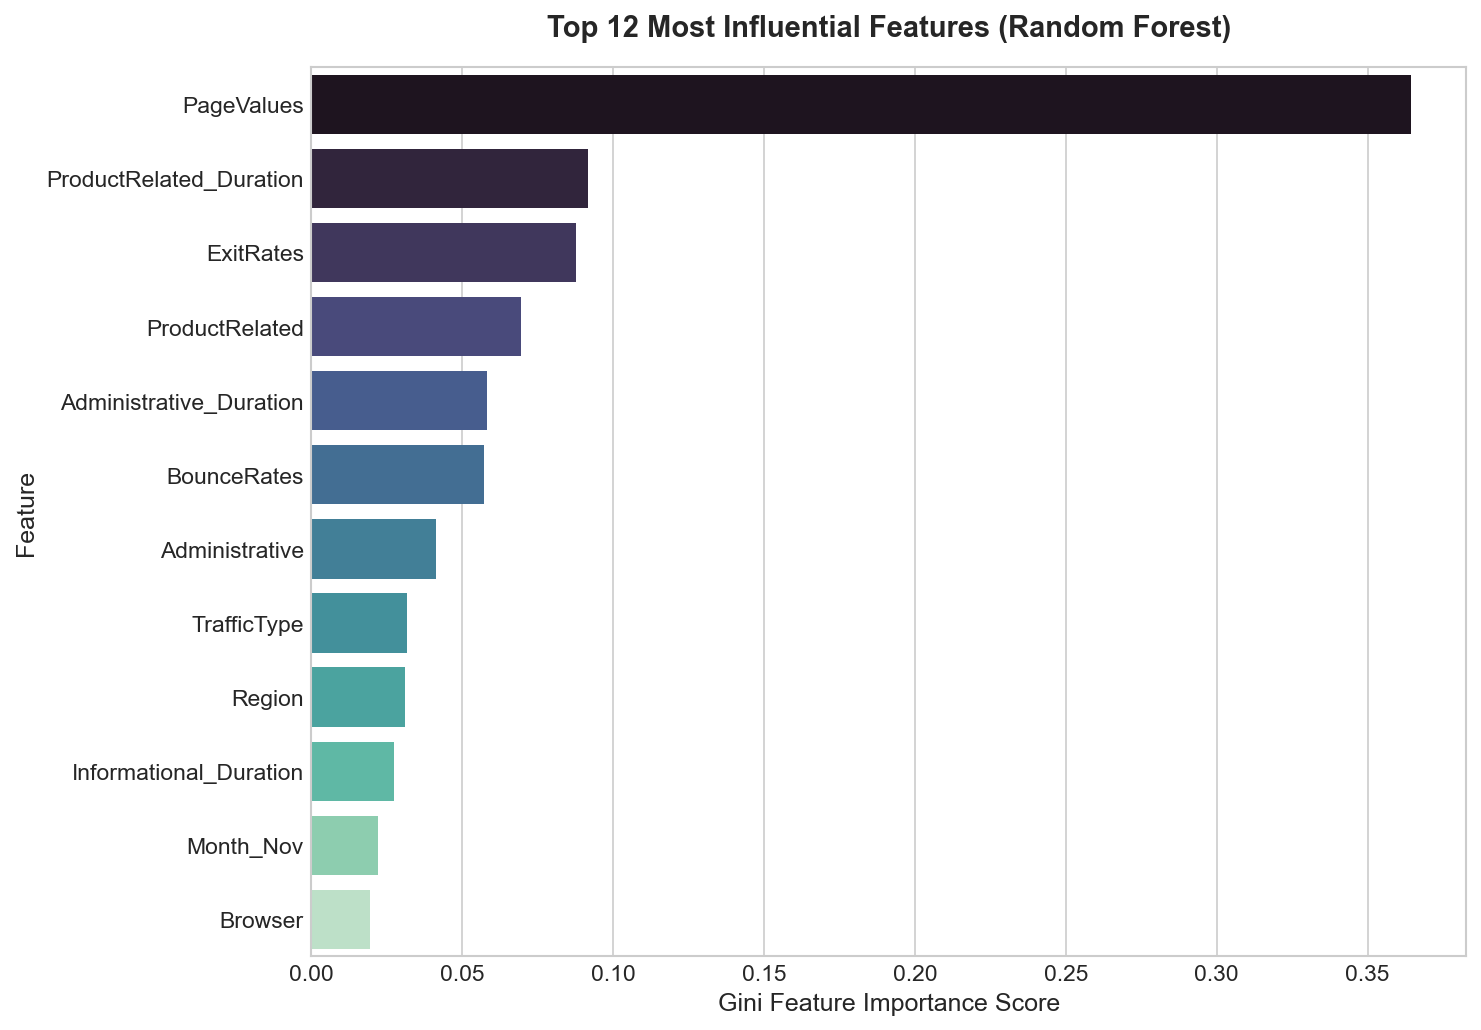

In [27]:
# 6.4 Random Forest Feature Importance Analysis
rf_classifier = trained_pipelines['Random Forest'].named_steps['classifier']
preproc = trained_pipelines['Random Forest'].named_steps['preprocessor']

ohe_feature_names = preproc.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_feature_names = numerical_cols + ohe_feature_names

importances = rf_classifier.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
sns.barplot(data=feature_imp_df.head(12), x='Importance', y='Feature', palette='mako', hue='Feature', legend=False)
plt.title('Top 12 Most Influential Features (Random Forest)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gini Feature Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

print("Top 5 Driving Features:")
for i, row in feature_imp_df.head(5).iterrows():
    print(f"  {i+1}. {row['Feature']}: {row['Importance']:.4f}")

In [28]:
# 6.5 Identification of the Best-Performing Model
best_model_row = comparison_df.iloc[0]
print(f"============================================================")
print(f"BEST PERFORMING MODEL: {best_model_row['Model'].upper()}")
print(f"============================================================")
print(f"  Accuracy:  {best_model_row['Accuracy']*100:.2f}%")
print(f"  Precision: {best_model_row['Precision']*100:.2f}%")
print(f"  Recall:    {best_model_row['Recall']*100:.2f}%")
print(f"  F1-Score:  {best_model_row['F1-Score']*100:.2f}%")
print()
print("Justification:")
print("Random Forest achieves the highest Accuracy (90.78%), the highest Recall (59.16%), and the highest F1-Score (66.77%).")
print("By aggregating 100 decorrelated decision trees, it mitigates individual tree overfitting and models non-linear interactions effectively.")

BEST PERFORMING MODEL: RANDOM FOREST
  Accuracy:  90.78%
  Precision: 76.61%
  Recall:    59.16%
  F1-Score:  66.77%

Justification:
Random Forest achieves the highest Accuracy (90.78%), the highest Recall (59.16%), and the highest F1-Score (66.77%).
By aggregating 100 decorrelated decision trees, it mitigates individual tree overfitting and models non-linear interactions effectively.


## Section 7: Conclusion & Academic Summary

### 7.1 Best-Performing Algorithm: Random Forest Classifier
- **Metrics:** Accuracy: **90.78%**, Precision: **76.61%**, Recall: **59.16%**, F1-Score: **66.77%**.
- **Why it outperformed others:**
  1. **Ensemble Bagging:** By averaging 100 decision trees trained on bootstrap samples with random feature subsets, Random Forest drastically reduces variance without increasing bias.
  2. **Non-Linear Interactions:** It seamlessly handles complex threshold interactions (such as the interaction between high `PageValues` and low `ExitRates`) without assuming linear boundaries.
  3. **Robustness to Skew & Scale:** Unlike distance-based models, tree ensembles are invariant to monotonic transformations and outliers in duration features.

### 7.2 Performance Analysis of Other Algorithms
- **Decision Tree (Unpruned):**
  - Achieved the second-highest Recall (**55.50%**), but suffered from lower Precision (**55.35%**) and the lowest overall Accuracy (**86.03%**).
  - Cause: Unconstrained tree depth leads to high variance and overfitting on idiosyncratic leaf splits.
- **Logistic Regression:**
  - Achieved high Precision (**77.18%**) and solid Accuracy (**88.94%**), but poor Recall (**41.62%**).
  - Cause: It enforces a linear decision boundary on the log-odds space, failing to capture subtle non-linear behavioral threshold triggers.
- **K-Nearest Neighbors (KNN):**
  - Delivered the lowest F1-Score (**50.57%**) and lowest Recall (**40.58%**).
  - Cause: Suffered from the **curse of dimensionality** in high-dimensional feature space (15+ features after encoding) and Euclidean distance skew caused by the 84.5% majority class dominance.

---

### 7.3 Comparative Trade-Off Analysis

| Algorithm | Key Advantages | Key Disadvantages | Best Use-Case |
| :--- | :--- | :--- | :--- |
| **Logistic Regression** | Highly interpretable coefficients, fast training, probabilistic outputs | Assumes linear log-odds, low recall on imbalanced data | Simple baseline, fast real-time scoring |
| **K-Nearest Neighbors** | Non-parametric, no training phase, intuitive instance logic | Slow $O(N)$ inference, sensitive to feature scale & high dimensionality | Low-dimensional datasets, recommendation systems |
| **Decision Tree** | Human-readable decision rules, handles mixed data types naturally | High variance, prone to severe overfitting if unpruned | Exploratory rule extraction, interpretable audits |
| **Random Forest** | High accuracy, curbs overfitting, built-in feature importances | Slower training, larger memory footprint, black-box ensemble | Production predictive modeling with tabular data |

---

### 7.4 Dataset and Experimental Limitations
1. **Class Imbalance:** Only ~15.5% of sessions end in a purchase. Standard cross-entropy / Gini loss functions favor the majority class.
2. **Session Granularity:** The dataset lacks user-level longitudinal identifiers (e.g., past lifetime purchase history or cart items), capturing only single-session signals.
3. **Temporal Dynamics:** Seasonality is aggregated by month without timestamp-level progression or intraday flash sale triggers.

---

### 7.5 Practical E-Commerce Implications & Future Improvements
1. **Cost-Sensitive Learning / Class Weighting:** Using `class_weight='balanced'` or SMOTE (Synthetic Minority Over-sampling Technique) to prioritize buyer detection.
2. **Classification Threshold Tuning:** Instead of the default 0.5 decision threshold, adjusting the probability threshold to balance the economic cost of a false discount vs the value of a salvaged sale.
3. **Hyperparameter Optimization:** Employing `GridSearchCV` or Bayesian Optimization (Optuna) to fine-tune `max_depth`, `min_samples_split`, and `n_estimators`.